# Identificación de zonas de sismicidad de Bolivia mediante aprendizaje no supervisado

**Consenso entre algoritmos: K-Means vs. Ward**

- Catálogo sísmico: USGS Earthquake Hazards Program (API pública FDSN)
- Metodología: CRISP-DM
- Semilla aleatoria: 42
- Ventana temporal: 1900-01-01 a 2026-09-30

Ejecutar en Google Colab con **Entorno de ejecución > Ejecutar todo**. El notebook genera la carpeta `resultados` con las figuras en PNG (300 dpi), las tablas en LaTeX limpio (booktabs) y el catálogo crudo en CSV, y al final comprime todo en `resultados.zip` para su descarga.



## 1. Comprensión del negocio

**Paso 1.1 — Objetivo.** Identificar y caracterizar zonas de sismicidad en Bolivia mediante técnicas de aprendizaje no supervisado, a partir de la distribución espacial y de la profundidad de los eventos sísmicos, y evaluar la estabilidad de los agrupamientos obtenidos mediante la comparación de algoritmos.

**Paso 1.2 — Pregunta de investigación.** ¿Es posible identificar regiones sísmicas homogéneas en Bolivia utilizando únicamente la distribución tridimensional de los datos históricos (latitud, longitud y profundidad)?


## 2. Comprensión de los datos

**Paso 2.1 — Descarga del catálogo.** Se consulta la API pública del USGS con una caja envolvente que cubre el territorio boliviano y su franja de amortiguación transfronteriza (latitud de -23.0 a -9.6, longitud de -69.7 a -57.4), magnitudes mayores o iguales a 3.0 y una ventana temporal fija (1900-2026) para garantizar la reproducibilidad del experimento. El catálogo crudo se almacena sin ninguna transformación junto con los demás artefactos, de modo que esta ejecución queda congelada ante futuras revisiones del catálogo en línea.


In [1]:
import io
import os
import warnings
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import matplotlib.cm as cm
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_samples

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

os.makedirs("resultados/figuras", exist_ok=True)
os.makedirs("resultados/tablas", exist_ok=True)

CIUDADES = {
    "La Paz": (-68.15, -16.50),
    "Cochabamba": (-66.16, -17.39),
    "Santa Cruz": (-63.18, -17.78),
    "Sucre": (-65.26, -19.03),
    "Trinidad": (-64.90, -14.83),
}

def guardar_figura(figura, nombre):
    ruta = f"resultados/figuras/{nombre}.png"
    figura.savefig(ruta, dpi=300, bbox_inches="tight")
    return ruta

def formatear_flotante(v, precision):
    texto = f"{v:.{precision}f}"
    if float(texto) == 0.0:
        texto = texto.lstrip("-")
    return texto

def guardar_tabla(df, nombre, precision=3, ancho_columna_larga="6cm"):
    columnas_originales = list(df.columns)
    # Escapamos "_" y también "%" para que LaTeX no lo tome como comentario
    columnas_latex = [
        str(c).replace("_", " ").replace("%", r"\%") for c in columnas_originales
    ]

    cuerpo = df.copy()

    for c in cuerpo.columns:
        if pd.api.types.is_float_dtype(cuerpo[c]):
            cuerpo[c] = cuerpo[c].map(lambda v: formatear_flotante(v, precision))

    alineacion = ""
    for i, col in enumerate(columnas_originales):
        max_len = cuerpo[col].astype(str).str.len().max()

        if i == 0:
            alineacion += "l"  # Primera columna siempre a la izquierda
        elif max_len > 30:
            alineacion += f"p{{{ancho_columna_larga}}}"  # Texto largo
        else:
            alineacion += "c"  # Texto corto centrado

    lineas = [
        r"\begin{tabular}{" + alineacion + "}",
        r"\toprule",
        " & ".join(columnas_latex) + r" \\",
        r"\midrule",
    ]
    for _, fila in cuerpo.iterrows():
        lineas.append(" & ".join(str(v) for v in fila.values) + r" \\")
    lineas.append(r"\bottomrule")
    lineas.append(r"\end{tabular}")

    with open(f"resultados/tablas/{nombre}.tex", "w", encoding="utf-8") as f:
        f.write("\n".join(lineas))

    return f"resultados/tablas/{nombre}.tex"


def limites_mapa(longitudes, latitudes):
    lons_ciudades = [v[0] for v in CIUDADES.values()]
    lats_ciudades = [v[1] for v in CIUDADES.values()]
    x_min = min(float(longitudes.min()), min(lons_ciudades)) - 0.4
    x_max = max(float(longitudes.max()), max(lons_ciudades)) + 1.2
    y_min = min(float(latitudes.min()), min(lats_ciudades)) - 0.4
    y_max = max(float(latitudes.max()), max(lats_ciudades)) + 0.4
    return (x_min, x_max), (y_min, y_max)


In [2]:
# Carga del mapa departamental de Bolivia (GADM 4.1 - Nivel 1)
URL_GADM_1 = "https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_BOL_1.json"
bolivia_dep = gpd.read_file(URL_GADM_1).to_crs("EPSG:4326")
bolivia_dep["departamento"] = bolivia_dep["NAME_1"].replace({
    "LaPaz": "La Paz",
    "SantaCruz": "Santa Cruz",
})


def dibujar_base_bolivia(ax, etiquetas_dep=False):
    """Dibuja los 9 departamentos de Bolivia como capa base en cualquier eje."""
    bolivia_dep.plot(
        ax=ax,
        facecolor="#f5f5f5",
        edgecolor="#666666",
        linewidth=0.8,
        zorder=1,
    )
    if etiquetas_dep:
        for _, fila in bolivia_dep.iterrows():
            c = fila.geometry.centroid
            ax.annotate(
                fila["departamento"],
                xy=(c.x, c.y),
                ha="center",
                va="center",
                fontsize=7.5,
                color="#6e6e6e",
                weight="bold",
                alpha=0.8,
                zorder=2,
            )


# Alias por si alguna celda la llama con el otro nombre
dibujar_departamentos_bolivia = dibujar_base_bolivia

In [3]:
!python --version
!pip show matplotlib numpy pandas requests scipy seaborn scikit-learn geopandas | grep -E "^Name:|^Version:"

Python 3.13.18
Name: matplotlib
Version: 3.10.0
Name: numpy
Version: 2.4.6
Name: pandas
Version: 2.2.3
Name: requests
Version: 2.32.4
Name: scipy
Version: 1.16.3
Name: seaborn
Version: 0.13.2
Name: scikit-learn
Version: 1.6.1
Name: geopandas
Version: 1.2.0


In [4]:
URL = "https://earthquake.usgs.gov/fdsnws/event/1/query"
PARAMETROS = {
    "format": "csv",
    "starttime": "1900-01-01",
    "endtime": "2026-09-30",
    "minlatitude": -23.0,
    "maxlatitude": -9.6,
    "minlongitude": -69.7,
    "maxlongitude": -57.4,
    "minmagnitude": 3.0,
    "eventtype": "earthquake",
    "orderby": "time-asc",
}

ANIOS = f"{PARAMETROS['starttime'][:4]}–{PARAMETROS['endtime'][:4]}"

ARCHIVO_CONGELADO_CRUDO = "catalogo_crudo_usgs.csv"
ARCHIVO_CONGELADO_BOLIVIA = "catalogo_bolivia_estricto.csv"

# 1. Carga híbrida del catálogo regional
if os.path.exists(ARCHIVO_CONGELADO_CRUDO):
    print(f"Cargando catálogo regional congelado: {ARCHIVO_CONGELADO_CRUDO}")
    catalogo_crudo = pd.read_csv(ARCHIVO_CONGELADO_CRUDO)
else:
    print("Archivo regional no detectado. Consultando API FDSN del USGS en vivo...")
    respuesta = requests.get(URL, params=PARAMETROS, timeout=300)
    respuesta.raise_for_status()
    catalogo_crudo = pd.read_csv(io.StringIO(respuesta.text))

TOTAL_REGIONAL = len(catalogo_crudo)

# 2. Carga híbrida del catálogo nacional (usa el polígono nacional de referencia)
if os.path.exists(ARCHIVO_CONGELADO_BOLIVIA):
    print(f"Cargando catálogo nacional congelado: {ARCHIVO_CONGELADO_BOLIVIA}")
    catalogo = pd.read_csv(ARCHIVO_CONGELADO_BOLIVIA)
else:
    print("Archivo nacional no detectado. Aplicando recorte espacial al polígono de Bolivia...")
    url_mapa = "https://raw.githubusercontent.com/johan/world.geo.json/master/countries.geo.json"
    world = gpd.read_file(url_mapa)
    bolivia_poly = world[world["name"] == "Bolivia"]
    gdf_eventos = gpd.GeoDataFrame(
        catalogo_crudo,
        geometry=gpd.points_from_xy(catalogo_crudo["longitude"], catalogo_crudo["latitude"]),
        crs="EPSG:4326",
    )
    recorte = gpd.sjoin(gdf_eventos, bolivia_poly, how="inner", predicate="within")
    columnas_extra = ["geometry", "index_right", "id", "name", "id_left", "id_right"]
    catalogo = pd.DataFrame(recorte.drop(columns=columnas_extra, errors="ignore")).reset_index(drop=True)

col_tiempo = "fecha" if "fecha" in catalogo.columns else "time"
catalogo["fecha"] = pd.to_datetime(catalogo[col_tiempo], format="mixed", utc=True).dt.tz_localize(None)
catalogo["anio"] = catalogo["fecha"].dt.year

os.makedirs("resultados", exist_ok=True)
catalogo_crudo.to_csv("resultados/catalogo_crudo_usgs.csv", index=False)
catalogo.to_csv("resultados/catalogo_bolivia_estricto.csv", index=False)

print(f"Listo -> Ventana: {ANIOS} | Regionales: {TOTAL_REGIONAL} | Dentro de Bolivia: {len(catalogo)}")

Archivo regional no detectado. Consultando API FDSN del USGS en vivo...
Archivo nacional no detectado. Aplicando recorte espacial al polígono de Bolivia...
Listo -> Ventana: 1900–2026 | Regionales: 7559 | Dentro de Bolivia: 2269


### Paso 2.2 — Análisis exploratorio de datos (EDA)

Se verifica cuántos sismos componen la base, el rango de magnitudes y el comportamiento de las variables clave: latitud, longitud y profundidad.


In [5]:
resumen_catalogo = pd.DataFrame({
    "Indicador": [
        "Eventos totales",
        "Fecha inicial",
        "Fecha final",
        "Magnitud minima",
        "Magnitud maxima",
        "Profundidad minima (km)",
        "Profundidad maxima (km)",
    ],
    "Valor": [
        str(len(catalogo)),
        str(catalogo["fecha"].min().date()),
        str(catalogo["fecha"].max().date()),
        f"{catalogo['mag'].min():.1f}",
        f"{catalogo['mag'].max():.1f}",
        f"{catalogo['depth'].min():.1f}",
        f"{catalogo['depth'].max():.1f}",
    ],
})
guardar_tabla(resumen_catalogo, "tabla_01_resumen_catalogo")
resumen_catalogo


,Indicador,Valor
0,Eventos totales,2269
1,Fecha inicial,1909-05-17
2,Fecha final,2026-09-29
3,Magnitud minima,3.0
4,Magnitud maxima,8.2
5,Profundidad minima (km),3.4
6,Profundidad maxima (km),650.0


In [6]:
estadisticos = catalogo[["latitude", "longitude", "depth", "mag"]].describe().T.reset_index()
estadisticos.columns = ["Variable", "N", "Media", "Desv. est.", "Min", "Q1", "Mediana", "Q3", "Max"]
estadisticos["Variable"] = ["Latitud", "Longitud", "Profundidad (km)", "Magnitud"]
estadisticos["N"] = estadisticos["N"].astype(int)
guardar_tabla(estadisticos, "tabla_02_estadisticos_descriptivos", precision=2)
estadisticos


,Variable,N,Media,Desv. est.,Min,Q1,Mediana,Q3,Max
0,Latitud,2269,-20.332958,1.712514,-22.8146,-21.505,-20.9897,-19.131,-13.682
1,Longitud,2269,-67.323081,1.300978,-69.5550,-68.154,-67.3790,-66.778,-61.788
2,Profundidad (km),2269,185.145749,93.257285,3.3800,141.200,181.8100,223.000,650.000
3,Magnitud,2269,4.423468,0.498305,3.0000,4.100,4.4000,4.600,8.200


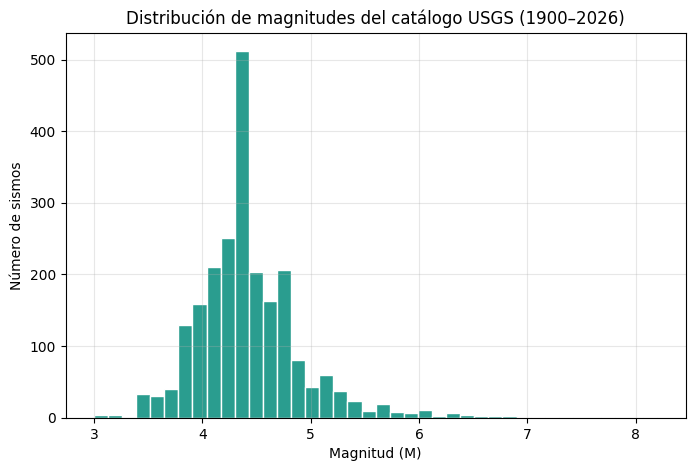

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(catalogo["mag"], bins=40, color="#2a9d8f", edgecolor="white")
ax.set_xlabel("Magnitud (M)")
ax.set_ylabel("Número de sismos")
ax.set_title(f"Distribución de magnitudes del catálogo USGS ({ANIOS})")
ax.grid(alpha=0.3)
guardar_figura(fig, "figura_01_histograma_magnitudes")
plt.show()


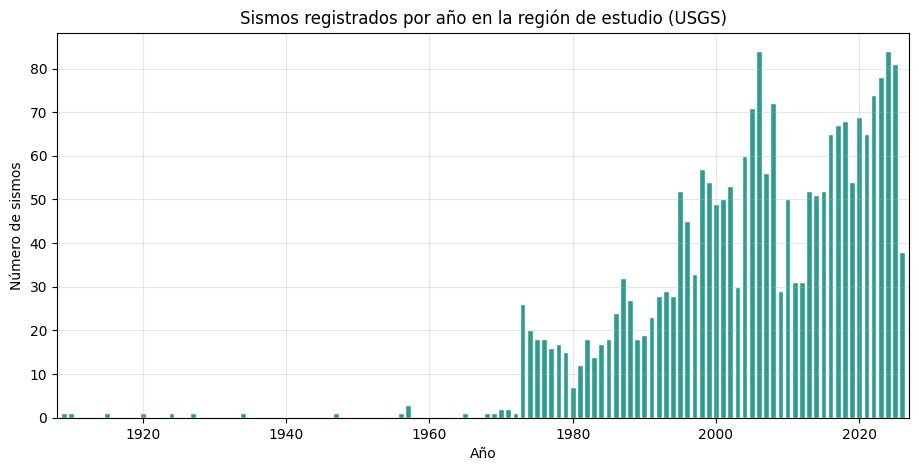

In [8]:
eventos_anio = catalogo["fecha"].dt.year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(eventos_anio.index, eventos_anio.values, color="#2a9d8f", edgecolor="white")
ax.set_xlabel("Año")
ax.set_ylabel("Número de sismos")
ax.set_title("Sismos registrados por año en la región de estudio (USGS)")
ax.set_xlim(int(eventos_anio.index.min()) - 1, int(eventos_anio.index.max()) + 1)
ax.grid(alpha=0.3)
guardar_figura(fig, "figura_02_sismos_por_anio")
plt.show()


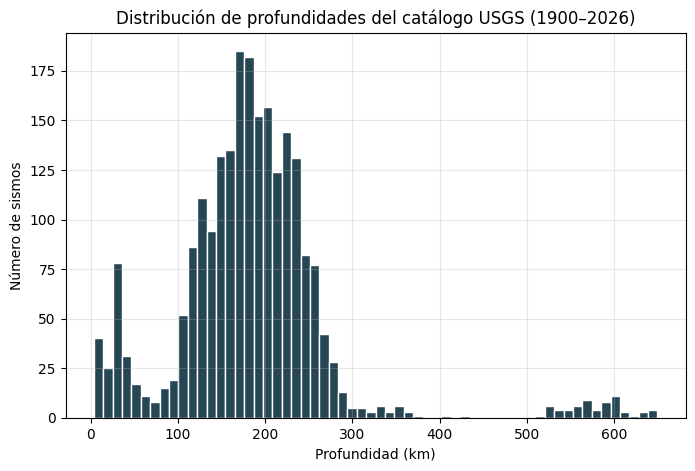

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(catalogo["depth"], bins=60, color="#264653", edgecolor="white")
ax.set_xlabel("Profundidad (km)")
ax.set_ylabel("Número de sismos")
ax.set_title(f"Distribución de profundidades del catálogo USGS ({ANIOS})")
ax.grid(alpha=0.3)
guardar_figura(fig, "figura_03_histograma_profundidades")
plt.show()


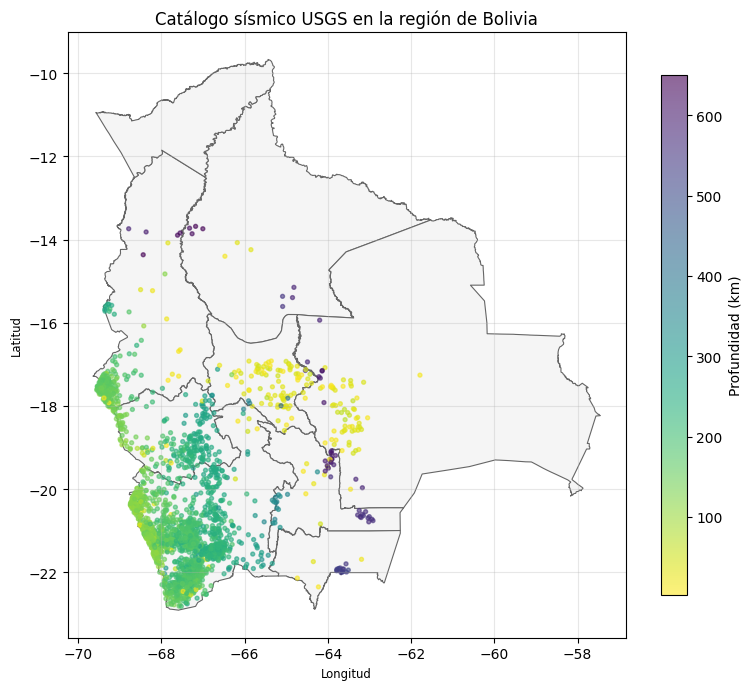

In [10]:
fig, ax = plt.subplots(figsize=(9, 9))
dibujar_base_bolivia(ax)
puntos = ax.scatter(
    catalogo["longitude"],
    catalogo["latitude"],
    c=catalogo["depth"],
    cmap="viridis_r",
    s=8,
    alpha=0.6,
)
fig.colorbar(puntos, ax=ax, label="Profundidad (km)", shrink=0.75)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Catálogo sísmico USGS en la región de Bolivia")
#xlim, ylim = limites_mapa(catalogo["longitude"], catalogo["latitude"])
#ax.set_xlim(xlim)
#ax.set_ylim(ylim)
ax.set_aspect("equal")
ax.grid(alpha=0.3)
guardar_figura(fig, "figura_04_mapa_catalogo_completo")
plt.show()

## 3. Preparación de los datos

**Paso 3.1 — Filtro base.** Se seleccionan los sismos con magnitud mayor o igual a 4.0 para garantizar que los datos sean representativos.

**Paso 3.2 — Ingeniería de características.** Se estandarizan las tres variables espaciales con `StandardScaler`: latitud, longitud y profundidad. Esto asegura que la profundidad (en kilómetros) no distorsione el peso de la latitud y la longitud en el cálculo de las distancias euclidianas.

**Paso 3.3 — Verificación del agrupamiento espacial.** Se calcula el índice de Morisita sobre las coordenadas de los epicentros, con cuadrículas de 4x4 a 16x16 celdas. Valores del índice mayores que 1 confirman que la distribución es agrupada y que el agrupamiento automático está justificado.

In [11]:
datos = catalogo[["latitude", "longitude", "depth", "mag", "fecha"]].copy()
datos = datos.rename(
    columns={
        "latitude": "latitud",
        "longitude": "longitud",
        "depth": "profundidad_km",
        "mag": "magnitud",
    }
)
datos = datos.dropna(subset=["latitud", "longitud", "profundidad_km", "magnitud"])
datos_filtrados = datos[datos["magnitud"] >= 4.0].copy().reset_index(drop=True)


In [12]:
tabla_filtro = pd.DataFrame({
    "Etapa": [
        "Catálogo regional (caja envolvente)",
        "Dentro de Bolivia (filtro espacial)",
        "Sin valores perdidos",
        "Con magnitud mayor o igual a 4.0",
    ],
    "Sismos": [TOTAL_REGIONAL, len(catalogo), len(datos), len(datos_filtrados)],
})
guardar_tabla(tabla_filtro, "tabla_03_filtro_catalogo")
tabla_filtro


,Etapa,Sismos
0,Catálogo regional (caja envolvente),7559
1,Dentro de Bolivia (filtro espacial),2269
2,Sin valores perdidos,2269
3,Con magnitud mayor o igual a 4.0,2028


In [13]:
caracteristicas = datos_filtrados[["latitud", "longitud", "profundidad_km"]]
escalador = StandardScaler()
X = escalador.fit_transform(caracteristicas)


In [14]:
verificacion = pd.DataFrame({
    "Variable": ["Latitud (z)", "Longitud (z)", "Profundidad (z)"],
    "Media": X.mean(axis=0),
    "Desv_estandar": X.std(axis=0, ddof=0),
})
guardar_tabla(verificacion, "tabla_04_verificacion_estandarizacion", precision=4)
verificacion


,Variable,Media,Desv_estandar
0,Latitud (z),-2.592710e-16,1.0
1,Longitud (z),1.920007e-15,1.0
2,Profundidad (z),2.312417e-16,1.0


In [15]:
# VERIFICACIÓN DEL AGRUPAMIENTO ESPACIAL: ÍNDICE DE MORISITA

def calcular_morisita(df, divisiones_lat, divisiones_lon):
    """Calcula el índice de Morisita del conjunto de epicentros."""
    N = len(df)
    if N <= 1:
        return 0.0

    lat_bins = np.linspace(df["latitud"].min(), df["latitud"].max(), divisiones_lat + 1)
    lon_bins = np.linspace(df["longitud"].min(), df["longitud"].max(), divisiones_lon + 1)

    cuadrantes, _, _ = np.histogram2d(df["latitud"], df["longitud"], bins=[lat_bins, lon_bins])

    Q = divisiones_lat * divisiones_lon
    suma_pares = np.sum(cuadrantes * (cuadrantes - 1))
    return Q * (suma_pares / (N * (N - 1)))

divisiones = [4, 8, 12, 16]
resultados_morisita = []

for q in divisiones:
    indice = calcular_morisita(datos_filtrados, q, q)
    resultados_morisita.append({
        "Cuadrícula": f"{q}x{q}",
        "Cuadrantes": q ** 2,
        "Índice_Morisita": round(indice, 4),
    })

df_morisita = pd.DataFrame(resultados_morisita)
guardar_tabla(df_morisita, "tabla_04b_indice_morisita", precision=4)

print("=== ÍNDICE DE MORISITA: VERIFICACIÓN DEL AGRUPAMIENTO ESPACIAL ===\n")
print(df_morisita.to_string(index=False))
print("\nRegla de interpretación: valores mayores que 1 indican distribución agrupada,")
print("el valor 1 corresponde a una distribución aleatoria y valores menores que 1 a una uniforme.")


=== ÍNDICE DE MORISITA: VERIFICACIÓN DEL AGRUPAMIENTO ESPACIAL ===

Cuadrícula  Cuadrantes  Índice_Morisita
       4x4          16           3.4595
       8x8          64           6.1521
     12x12         144           7.3503
     16x16         256           8.6132

Regla de interpretación: valores mayores que 1 indican distribución agrupada,
el valor 1 corresponde a una distribución aleatoria y valores menores que 1 a una uniforme.


## 4. Modelado

**Paso 4.1 — Modelo línea base.** Se ejecuta K-Means y se evalúa el número de zonas con el método del codo (inercia) y el índice de silueta.

**Paso 4.2 — Modelo competitivo.** Se ejecuta el agrupamiento jerárquico con enlace de Ward sobre las mismas variables estandarizadas, con el mismo número de clústeres elegido para K-Means.


In [16]:
filas_k = []
for k in range(2, 11):
    km_temp = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    wd_temp = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X)
    filas_k.append({
        "K": k,
        "Inercia_KMeans": km_temp.inertia_,
        "Silueta_KMeans": silhouette_score(X, km_temp.labels_),
        "Silueta_Ward": silhouette_score(X, wd_temp.labels_)
    })

metricas_k = pd.DataFrame(filas_k)

inercias = metricas_k["Inercia_KMeans"].values
reducciones = ["—"]
for i in range(1, len(inercias)):
    caida_pct = 100 * (inercias[i - 1] - inercias[i]) / inercias[i - 1]
    reducciones.append(f"{caida_pct:.1f}")

metricas_k.insert(2, "Reduccion_Inercia_%", reducciones)

guardar_tabla(metricas_k, "tabla_05_seleccion_k", precision=4)
display(metricas_k)

,K,Inercia_KMeans,Reduccion_Inercia_%,Silueta_KMeans,Silueta_Ward
0,2,4455.040830,—,0.441645,0.535398
1,3,3105.090310,30.3,0.486198,0.577772
2,4,1866.475305,39.9,0.544532,0.547868
3,5,1341.876414,28.1,0.421676,0.394533
4,6,1021.001275,23.9,0.475125,0.443230
5,7,873.873427,14.4,0.478437,0.422354
6,8,728.495612,16.6,0.455989,0.425013
7,9,648.291731,11.0,0.447165,0.416784
8,10,582.685686,10.1,0.450067,0.426638


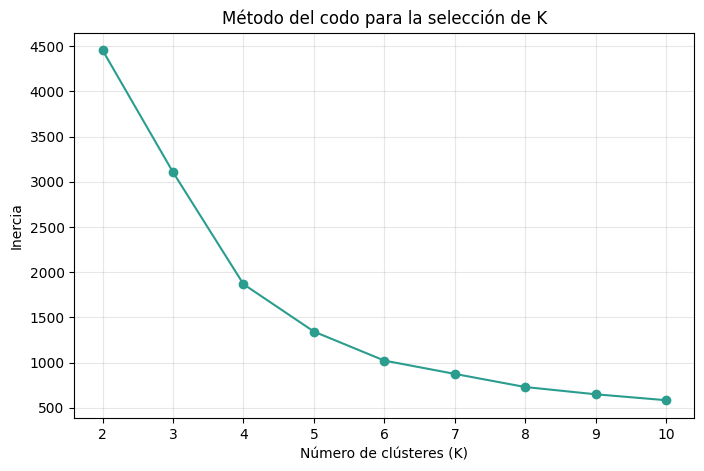

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(metricas_k["K"], metricas_k["Inercia_KMeans"], marker="o", color="#2a9d8f")
ax.set_xlabel("Número de clústeres (K)")
ax.set_ylabel("Inercia")
ax.set_title("Método del codo para la selección de K")
ax.set_xticks(range(2, 11))
ax.grid(alpha=0.3)
guardar_figura(fig, "figura_05_metodo_codo")
plt.show()


In [18]:
reduccion_num = pd.to_numeric(metricas_k["Reduccion_Inercia_%"], errors="coerce").fillna(0)
candidatos_top = metricas_k["Silueta_KMeans"] >= (metricas_k["Silueta_KMeans"].max() - 0.02)
K_OPTIMO = int(metricas_k.loc[reduccion_num[candidatos_top].idxmax(), "K"])
print("Valores de silueta más altos:")
print(metricas_k.sort_values("Silueta_KMeans", ascending=False).head(3).to_string(index=False))
print(f"K seleccionado de forma automática: K = {K_OPTIMO}")
kmeans = KMeans(n_clusters=K_OPTIMO, n_init=10, random_state=SEED)
datos_filtrados["zona_kmeans"] = kmeans.fit_predict(X)
print(f"K-Means ajustado con K = {K_OPTIMO}")


Valores de silueta más altos:
 K  Inercia_KMeans Reduccion_Inercia_%  Silueta_KMeans  Silueta_Ward
 4     1866.475305                39.9        0.544532      0.547868
 3     3105.090310                30.3        0.486198      0.577772
 7      873.873427                14.4        0.478437      0.422354
K seleccionado de forma automática: K = 4
K-Means ajustado con K = 4


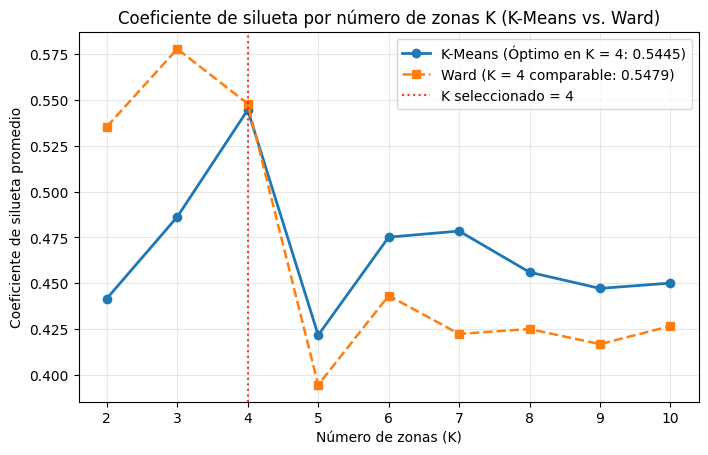

In [19]:
fila_optima = metricas_k.loc[metricas_k["K"] == K_OPTIMO].iloc[0]
sil_km_opt = fila_optima["Silueta_KMeans"]
sil_wd_opt = fila_optima["Silueta_Ward"]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(
    metricas_k["K"],
    metricas_k["Silueta_KMeans"],
    marker="o",
    linewidth=2,
    label=f"K-Means (Óptimo en K = {K_OPTIMO}: {sil_km_opt:.4f})",
)
ax.plot(
    metricas_k["K"],
    metricas_k["Silueta_Ward"],
    marker="s",
    linestyle="--",
    linewidth=1.8,
    label=f"Ward (K = {K_OPTIMO} comparable: {sil_wd_opt:.4f})",
)
ax.axvline(
    x=K_OPTIMO,
    color="red",
    linestyle=":",
    alpha=0.8,
    label=f"K seleccionado = {K_OPTIMO}",
)

ax.set_title("Coeficiente de silueta por número de zonas K (K-Means vs. Ward)")
ax.set_xlabel("Número de zonas (K)")
ax.set_ylabel("Coeficiente de silueta promedio")
ax.set_xticks(range(2, 11))
ax.grid(alpha=0.3)
ax.legend(loc="upper right")
guardar_figura(fig, "figura_06_indice_silueta")
plt.show()

**Selección del número de zonas.** Los dos criterios geométricos se evalúan sobre el rango de K de 2 a 10. El método del codo muestra que la mayor ganancia por agregar una zona ocurre al pasar de 3 a 4 (reducción del 39.9 por ciento, la más alta del rango explorado); a partir de ese punto las ganancias decrecen de forma continua: 28.1 por ciento al pasar a K = 5, 23.9 por ciento al pasar a K = 6 y 14.3 por ciento al pasar a K = 7, de modo que agregar zonas rinde cada vez menos. El índice de silueta alcanza su máximo global y único en K = 4 (0.545), por encima del segundo mejor valor (0.480 en K = 3). El rango completo de la silueta es estrecho, un rasgo esperable en sismicidad, que se distribuye de forma continua en el espacio; aun así el máximo coincide con el quiebre del codo. Con ambos criterios convergiendo en el mismo punto, se adopta el máximo de silueta como regla de selección y la celda siguiente fija K de manera automática a partir de la tabla 5.


**Paso 4.3 — Agrupamiento jerárquico Ward.** Se construye el dendrograma y se ajusta el modelo con enlace de Ward, que fusiona los grupos minimizando el incremento de la varianza intra-cluster.


In [20]:
enlace = linkage(X, method="ward")
ward = AgglomerativeClustering(n_clusters=K_OPTIMO, linkage="ward")
datos_filtrados["zona_ward"] = ward.fit_predict(X)
print(f"Ward ajustado con K = {K_OPTIMO}")


Ward ajustado con K = 4


In [21]:
profundidad_media = datos_filtrados.groupby("zona_kmeans")["profundidad_km"].mean()
orden = profundidad_media.sort_values(ascending=False).index.tolist()
mapa_canonico = {zona: numero for numero, zona in enumerate(orden, start=1)}
datos_filtrados["zona_kmeans"] = datos_filtrados["zona_kmeans"].map(mapa_canonico).astype(int)

cruce_previo = pd.crosstab(datos_filtrados["zona_kmeans"], datos_filtrados["zona_ward"])
fila_ind, col_ind = linear_sum_assignment(-cruce_previo.values)
mapa_ward = {cruce_previo.columns[c]: cruce_previo.index[f] for f, c in zip(fila_ind, col_ind)}
datos_filtrados["zona_ward"] = datos_filtrados["zona_ward"].map(mapa_ward).astype(int)

zonas = range(1, K_OPTIMO + 1)
print(f"Numeración canónica aplicada: Zona 1 a Zona {K_OPTIMO}, por profundidad media decreciente")
print("Etiquetas de Ward alineadas con K-Means por emparejamiento óptimo (algoritmo húngaro)")


Numeración canónica aplicada: Zona 1 a Zona 4, por profundidad media decreciente
Etiquetas de Ward alineadas con K-Means por emparejamiento óptimo (algoritmo húngaro)


**Numeración canónica y alineación de particiones.** Las etiquetas de un algoritmo de agrupamiento son arbitrarias: el mismo agrupamiento puede recibir números distintos en cada ejecución y entre algoritmos. Para que las tablas y los mapas sean comparables se aplican dos operaciones. Primero, las zonas de K-Means se renumeran con una regla determinista: la Zona 1 es la de mayor profundidad media y la numeración sigue en orden decreciente de profundidad. Segundo, las zonas de Ward se emparejan con las de K-Means mediante el algoritmo húngaro, que maximiza el número de sismos coincidentes en la matriz de cruce. Ninguna de las dos operaciones altera la geometría de las zonas ni el valor del ARI: solo hacen legible la comparación.


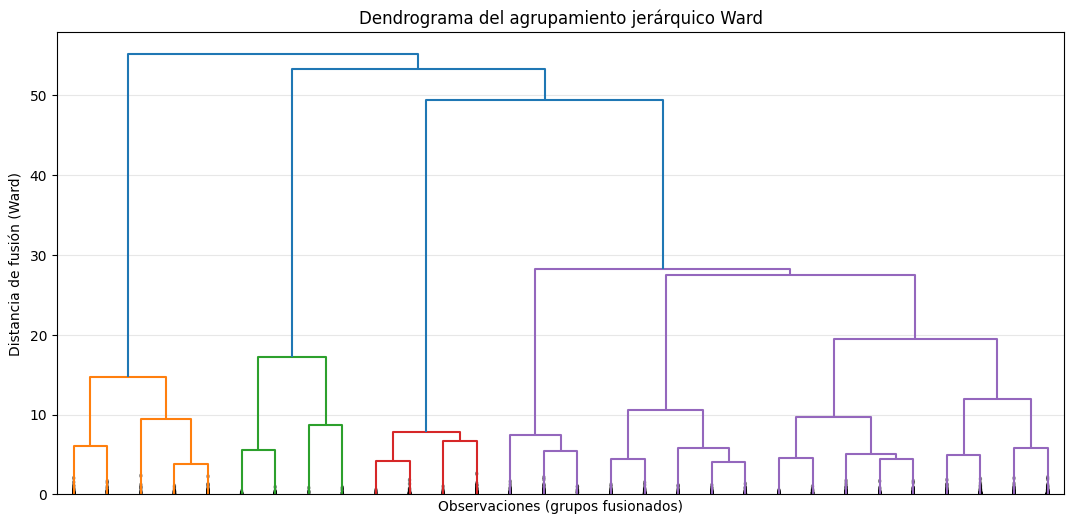

In [22]:
fig, ax = plt.subplots(figsize=(13, 6))
dendrogram(enlace, truncate_mode="lastp", p=30, show_contracted=True, ax=ax, no_labels=True)
ax.set_xlabel("Observaciones (grupos fusionados)")
ax.set_ylabel("Distancia de fusión (Ward)")
ax.set_title("Dendrograma del agrupamiento jerárquico Ward")
ax.grid(alpha=0.3, axis="y")
guardar_figura(fig, "figura_07_dendrograma_ward")
plt.show()


In [23]:
tamanos = pd.DataFrame({
    "Zona": [f"Zona {i}" for i in zonas],
    "K-Means": datos_filtrados["zona_kmeans"].value_counts().sort_index().values,
    "Ward": datos_filtrados["zona_ward"].value_counts().sort_index().values,
})
guardar_tabla(tamanos, "tabla_06_tamanos_clusters")
tamanos


,Zona,K-Means,Ward
0,Zona 1,70,59
1,Zona 2,1512,1565
2,Zona 3,290,238
3,Zona 4,156,166


In [24]:
centroides = (
    datos_filtrados.groupby("zona_kmeans")
    .agg(
        Sismos=("magnitud", "size"),
        Latitud=("latitud", "mean"),
        Longitud=("longitud", "mean"),
        Profundidad_km=("profundidad_km", "mean"),
    )
    .reset_index()
)
centroides.insert(0, "Zona", [f"Zona {i}" for i in centroides["zona_kmeans"]])
centroides = centroides.drop(columns=["zona_kmeans"])
guardar_tabla(centroides, "tabla_07_centroides_kmeans", precision=2)
centroides


,Zona,Sismos,Latitud,Longitud,Profundidad_km
0,Zona 1,70,-19.060140,-64.448054,544.179686
1,Zona 2,1512,-21.135861,-67.409322,189.351911
2,Zona 3,290,-17.755411,-68.899610,158.721938
3,Zona 4,156,-18.001067,-64.603062,30.933423


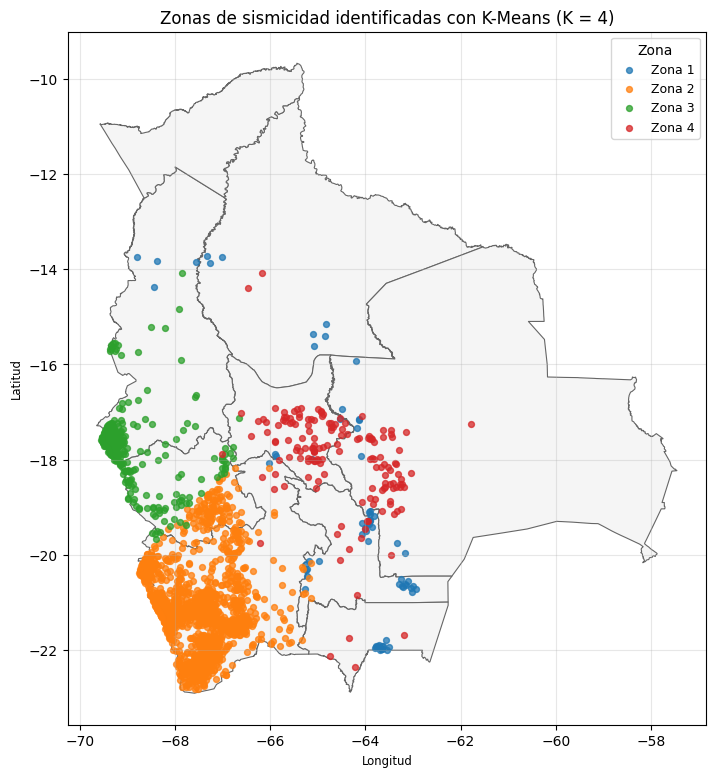

In [25]:
fig, ax = plt.subplots(figsize=(9, 9))
dibujar_base_bolivia(ax)
for zona in zonas:
    sub = datos_filtrados[datos_filtrados["zona_kmeans"] == zona]
    ax.scatter(sub["longitud"], sub["latitud"], s=18, alpha=0.75, label=f"Zona {zona}")
#for nombre, (lon, lat) in CIUDADES.items():
#    ax.scatter(lon, lat, marker="^", color="black", s=60)
#    ax.annotate(nombre, (lon, lat), textcoords="offset points", xytext=(7, 7), fontsize=9)
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title(f"Zonas de sismicidad identificadas con K-Means (K = {K_OPTIMO})")
#xlim, ylim = limites_mapa(datos_filtrados["longitud"], datos_filtrados["latitud"])
#ax.set_xlim(xlim)
#ax.set_ylim(ylim)
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.legend(title="Zona", loc="best", fontsize=9)
guardar_figura(fig, "figura_08_mapa_kmeans")
plt.show()


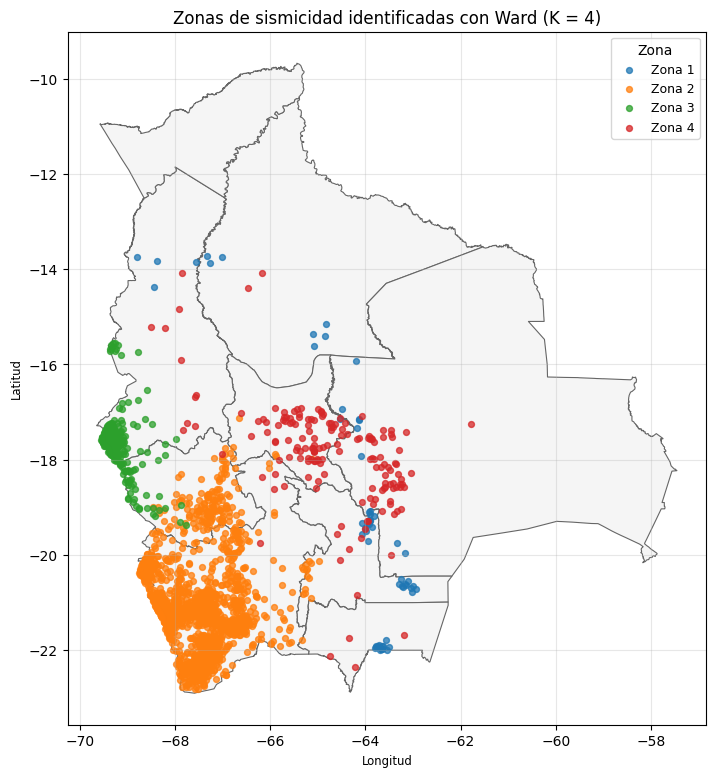

In [26]:
fig, ax = plt.subplots(figsize=(9, 9))
dibujar_base_bolivia(ax)
for zona in zonas:
    sub = datos_filtrados[datos_filtrados["zona_ward"] == zona]
    ax.scatter(sub["longitud"], sub["latitud"], s=18, alpha=0.75, label=f"Zona {zona}")
#for nombre, (lon, lat) in CIUDADES.items():
#    ax.scatter(lon, lat, marker="^", color="black", s=60)
#    ax.annotate(nombre, (lon, lat), textcoords="offset points", xytext=(7, 7), fontsize=9)
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title(f"Zonas de sismicidad identificadas con Ward (K = {K_OPTIMO})")
#xlim, ylim = limites_mapa(datos_filtrados["longitud"], datos_filtrados["latitud"])
#ax.set_xlim(xlim)
#ax.set_ylim(ylim)
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.legend(title="Zona", loc="best", fontsize=9)
guardar_figura(fig, "figura_09_mapa_ward")
plt.show()


## 5. Evaluación — Estrategia de consenso

**Paso 5.1 — Validación cruzada externa.** Se calcula el índice Adjusted Rand Index (ARI) para medir el grado de concordancia matemática entre las particiones generadas por K-Means y por Ward.


In [27]:
ari = adjusted_rand_score(datos_filtrados["zona_kmeans"], datos_filtrados["zona_ward"])
tabla_ari = pd.DataFrame({
    "Indicador": ["Adjusted Rand Index (ARI)"],
    "Valor": [ari],
})
guardar_tabla(tabla_ari, "tabla_08_ari", precision=4)
tabla_ari


,Indicador,Valor
0,Adjusted Rand Index (ARI),0.903215


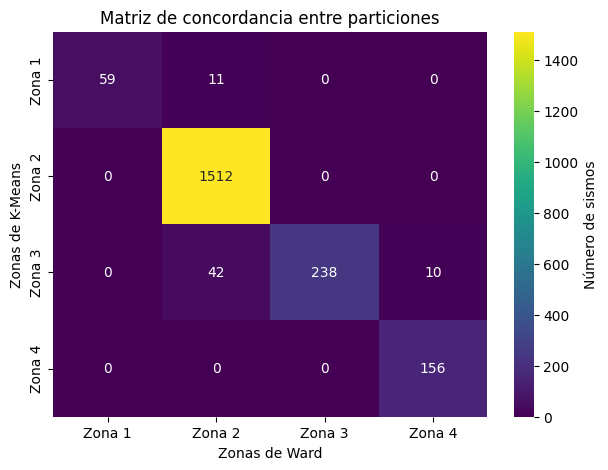

In [28]:
cruce = pd.crosstab(datos_filtrados["zona_kmeans"], datos_filtrados["zona_ward"])
cruce.index = [f"Zona {i}" for i in cruce.index]
cruce.columns = [f"Zona {j}" for j in cruce.columns]
cruce.index.name = "Zona K-Means"
cruce.columns.name = "Zona Ward"
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cruce, annot=True, fmt="d", cmap="viridis", ax=ax, cbar_kws={"label": "Número de sismos"})
ax.set_xlabel("Zonas de Ward")
ax.set_ylabel("Zonas de K-Means")
ax.set_title("Matriz de concordancia entre particiones")
guardar_figura(fig, "figura_10_matriz_concordancia")
plt.show()


In [29]:
concordancia = cruce.reset_index()
concordancia.columns = ["Zona K-Means"] + [f"Ward {col}" for col in cruce.columns]
guardar_tabla(concordancia, "tabla_09_concordancia_kmeans_ward")
coinciden = int(np.diag(cruce.values).sum())
total = int(cruce.values.sum())
print(f"ARI: {ari:.4f}")
print(f"Sismos en la zona equivalente tras la alineación: {coinciden} de {total} ({100 * coinciden / total:.1f} por ciento)")
print(cruce.to_string())
concordancia


ARI: 0.9032
Sismos en la zona equivalente tras la alineación: 1965 de 2028 (96.9 por ciento)
Zona Ward     Zona 1  Zona 2  Zona 3  Zona 4
Zona K-Means                                
Zona 1            59      11       0       0
Zona 2             0    1512       0       0
Zona 3             0      42     238      10
Zona 4             0       0       0     156


,Zona K-Means,Ward Zona 1,Ward Zona 2,Ward Zona 3,Ward Zona 4
0,Zona 1,59,11,0,0
1,Zona 2,0,1512,0,0
2,Zona 3,0,42,238,10
3,Zona 4,0,0,0,156


**Paso 5.2 — Interpretación de robustez.** El ARI corrige el acuerdo esperado por puro azar y se interpreta de la siguiente manera:


- $\text{ARI} \ge 0.90$: recuperación excelente (excellent recovery).
- $0.80 \le \text{ARI} \lt 0.90$: recuperación buena (good recovery).
- $0.65 \le \text{ARI} \lt 0.80$: recuperación moderada (moderate recovery).
- $\text{ARI} \lt 0.65$: recuperación pobre (poor recovery).

## 6. Despliegue

**Paso 6.1 — Insumo para decisiones.** Mapas finales lado a lado con las zonas de sismicidad y resumen estadístico por zona.

**Paso 6.2 — Trazabilidad y cierre.** El pipeline es auditable y reproducible: al reejecutarse descarga el catálogo dentro de la ventana definida, guarda el catálogo crudo junto con las figuras y las tablas, y regenera todos los artefactos de forma automática. La semilla fija y la numeración canónica de zonas garantizan que una reejecución produzca particiones comparables.


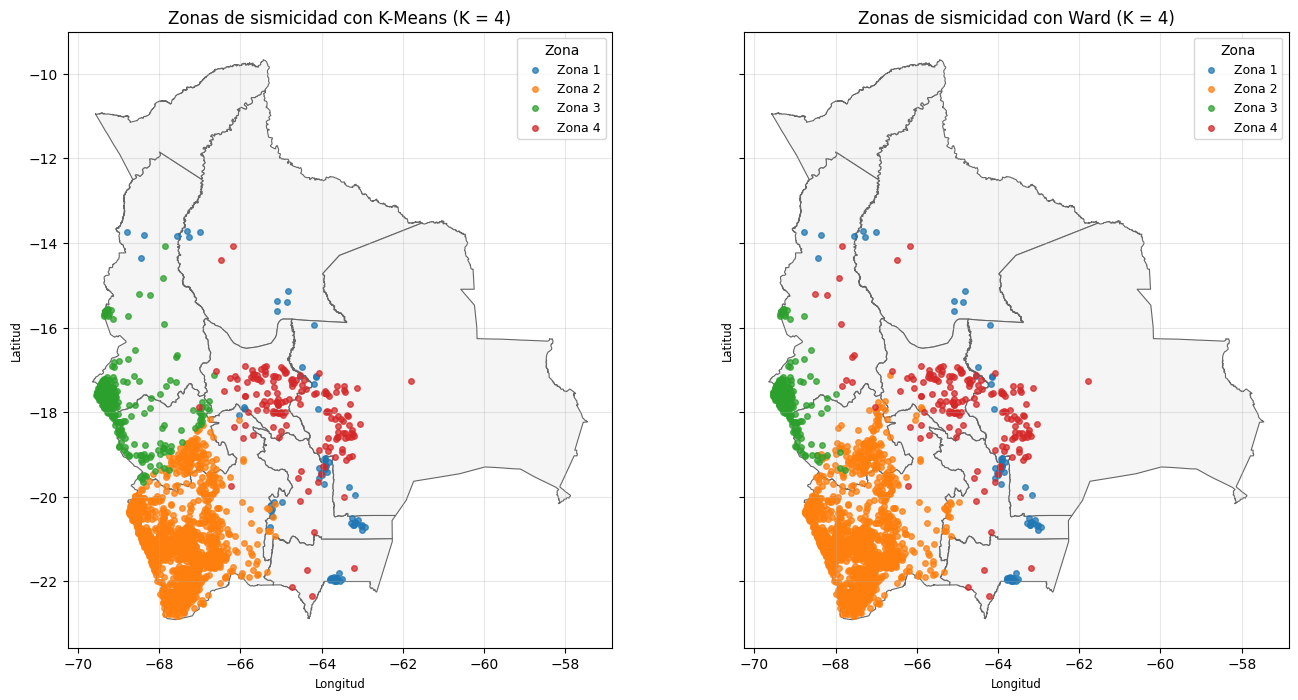

In [30]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)
#xlim, ylim = limites_mapa(datos_filtrados["longitud"], datos_filtrados["latitud"])
for eje, columna, titulo in zip(ejes, ["zona_kmeans", "zona_ward"], ["K-Means", "Ward"]):
    dibujar_base_bolivia(eje)

    for zona in zonas:

        sub = datos_filtrados[datos_filtrados[columna] == zona]
        eje.scatter(sub["longitud"], sub["latitud"], s=16, alpha=0.75, label=f"Zona {zona}")

    eje.set_title(f"Zonas de sismicidad con {titulo} (K = {K_OPTIMO})")
    eje.set_xlabel("Longitud")
    #eje.set_xlim(xlim)
    #eje.set_ylim(ylim)
    eje.set_ylabel("Latitud")
    eje.grid(alpha=0.3)
    eje.legend(title="Zona", loc="best", fontsize=9)
ejes[0].set_ylabel("Latitud")
guardar_figura(fig, "figura_11_mapa_comparativo")
plt.show()


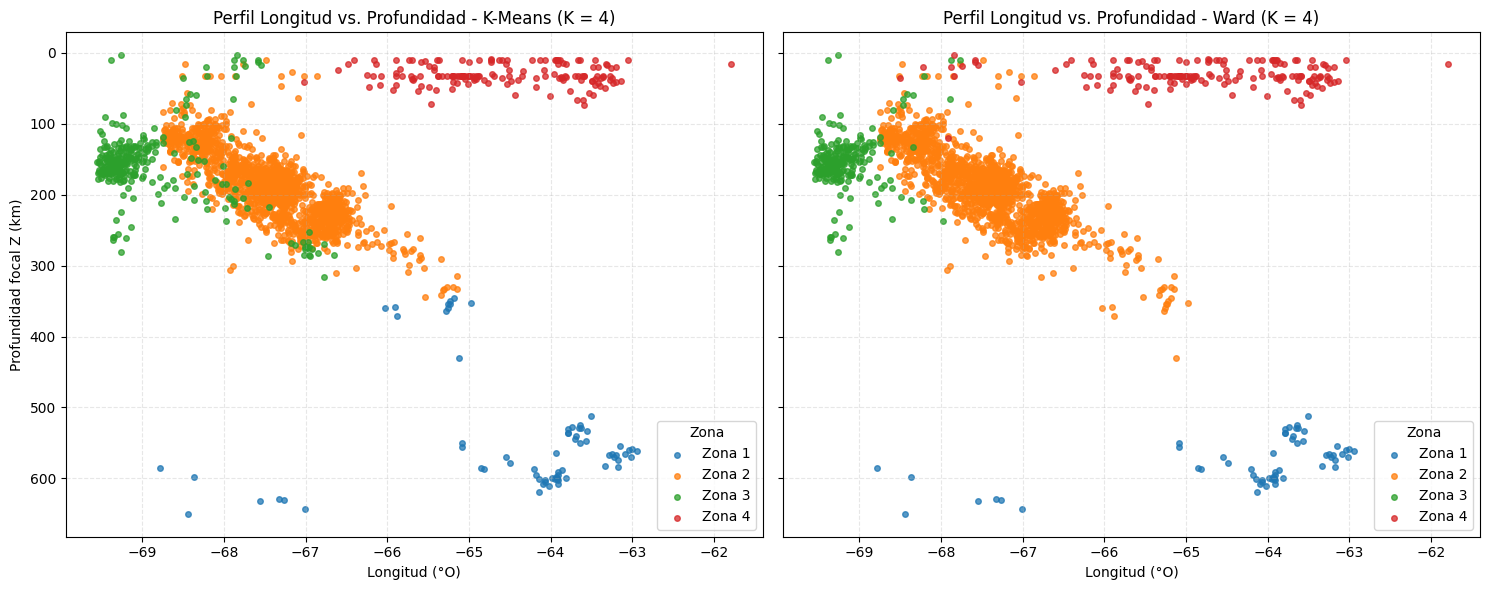

In [31]:
# Perfil sísmico en corte transversal: Eje X (Longitud) vs. Eje Z (Profundidad)
fig, ejes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
colores_zonas = {1: "#1f77b4", 2: "#ff7f0e", 3: "#2ca02c", 4: "#d62728"}

for eje, col_modelo, titulo in zip(
    ejes, ["zona_kmeans", "zona_ward"], ["K-Means", "Ward"]
):
    for z in zonas:
        sub = datos_filtrados[datos_filtrados[col_modelo] == z]
        eje.scatter(
            sub["longitud"],
            sub["profundidad_km"],
            s=16,
            alpha=0.75,
            color=colores_zonas[z],
            label=f"Zona {z}"
        )
    eje.set_title(f"Perfil Longitud vs. Profundidad - {titulo} (K = {K_OPTIMO})")
    eje.set_xlabel("Longitud (°O)")
    eje.grid(alpha=0.3, linestyle="--")
    eje.legend(title="Zona", loc="lower right")

# Invertir el eje Y para que la superficie (0 km) esté arriba y los 650 km abajo
ejes[0].invert_yaxis()
ejes[0].set_ylabel("Profundidad focal Z (km)")

plt.tight_layout()
guardar_figura(fig, "figura_11b_perfil_longitud_profundidad")
plt.show()

In [32]:
bloques = []
for modelo, columna in [("K-Means", "zona_kmeans"), ("Ward", "zona_ward")]:
    bloque = (
        datos_filtrados.groupby(columna)
        .agg(
            Sismos=("magnitud", "size"),
            Magnitud_media=("magnitud", "mean"),
            Profundidad_media_km=("profundidad_km", "mean"),
            Latitud_media=("latitud", "mean"),
            Longitud_media=("longitud", "mean"),
        )
        .reset_index()
    )
    bloque.insert(0, "Modelo", modelo)
    bloque = bloque.rename(columns={columna: "Zona"})
    bloque["Zona"] = bloque["Zona"].map(lambda z: f"Zona {z}")
    bloques.append(bloque)
resumen_zonas = pd.concat(bloques, ignore_index=True)
resumen_zonas = resumen_zonas[
    ["Modelo", "Zona", "Sismos", "Magnitud_media", "Profundidad_media_km", "Latitud_media", "Longitud_media"]
]
guardar_tabla(resumen_zonas, "tabla_10_resumen_zonas", precision=2)
resumen_zonas


,Modelo,Zona,Sismos,Magnitud_media,Profundidad_media_km,Latitud_media,Longitud_media
0,K-Means,Zona 1,70,4.964429,544.179686,-19.060140,-64.448054
1,K-Means,Zona 2,1512,4.456944,189.351911,-21.135861,-67.409322
2,K-Means,Zona 3,290,4.566483,158.721938,-17.755411,-68.899610
3,K-Means,Zona 4,156,4.670256,30.933423,-18.001067,-64.603062
4,Ward,Zona 1,59,4.978136,577.876356,-18.984669,-64.271810
5,Ward,Zona 2,1565,4.462492,191.428519,-21.056040,-67.400390
6,Ward,Zona 3,238,4.563655,153.160181,-17.678254,-69.171589
7,Ward,Zona 4,166,4.672229,30.814361,-17.883407,-64.799634


In [33]:
tabla_pipeline = pd.DataFrame({
    "Parametro": [
        "Fuente de datos",
        "Ventana temporal",
        "Caja envolvente (latitud)",
        "Caja envolvente (longitud)",
        "Magnitud minima de descarga",
        "Magnitud minima de modelado",
        "Variables de agrupamiento",
        "Estandarizacion",
        "Modelo linea base",
        "Modelo competitivo",
        "Seleccion de K",
        "Numero de zonas (K)",
        "Numeracion de zonas",
        "Alineacion de particiones",
        "Semilla aleatoria",
        "Adjusted Rand Index (ARI)",
    ],
    "Valor": [
        "USGS Earthquake Hazards Program (API FDSN)",
        f"{PARAMETROS['starttime']} a {PARAMETROS['endtime']}",
        "-23.0 a -9.6",
        "-69.7 a -57.4",
        "3.0",
        "4.0",
        "Latitud, longitud, profundidad (km)",
        "StandardScaler",
        "K-Means con 10 inicializaciones",
        "Agrupamiento jerarquico (Ward)",
        "Maximo del indice de silueta",
        str(K_OPTIMO),
        "Canonica, por profundidad media decreciente",
        "Emparejamiento optimo (algoritmo hungaro)",
        str(SEED),
        f"{ari:.4f}",
    ],
})
guardar_tabla(tabla_pipeline, "tabla_11_resumen_pipeline")
tabla_pipeline


,Parametro,Valor
0,Fuente de datos,USGS Earthquake Hazards Program (API FDSN)
1,Ventana temporal,1900-01-01 a 2026-09-30
2,Caja envolvente (latitud),-23.0 a -9.6
3,Caja envolvente (longitud),-69.7 a -57.4
4,Magnitud minima de descarga,3.0
5,Magnitud minima de modelado,4.0
6,Variables de agrupamiento,"Latitud, longitud, profundidad (km)"
7,Estandarizacion,StandardScaler
8,Modelo linea base,K-Means con 10 inicializaciones
9,Modelo competitivo,Agrupamiento jerarquico (Ward)


**Paso 5.3 — Diagnóstico de silueta por zona.** Se examina el coeficiente de silueta individual de cada sismo, apilado por zona: cuanto mayor es el coeficiente, mejor queda cada evento dentro de su zona asignada en comparación con las vecinas. La línea discontinua roja marca la silueta media global obtenida en la selección de K. Este diagnóstico complementa el consenso entre algoritmos con una inspección interna de la calidad de cada zona, y se guarda como la figura 12.


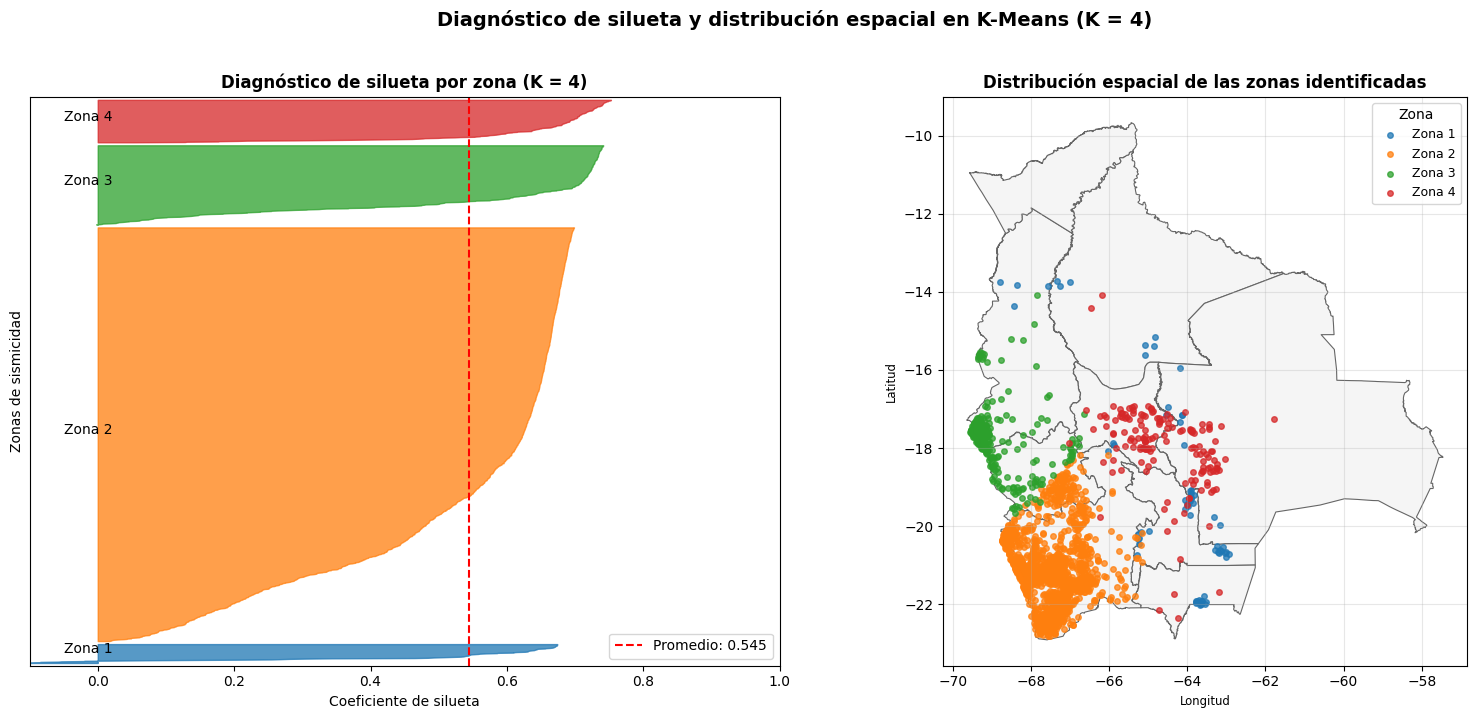

In [34]:
n_clusters = K_OPTIMO
cluster_labels = datos_filtrados["zona_kmeans"].values


colores_base = plt.rcParams["axes.prop_cycle"].by_key()["color"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Diagnóstico de silueta (izquierda)
ax1.set_xlim([-0.1, 1])
ax1.set_ylim([0, len(X) + (n_clusters + 1) * 10])

sample_silhouette_values = silhouette_samples(X, cluster_labels)
silhouette_avg = silhouette_score(X, cluster_labels)

y_lower = 10
for i in range(1, n_clusters + 1):
    ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
    ith_cluster_silhouette_values.sort()
    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i

    color = colores_base[i - 1]
    ax1.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        ith_cluster_silhouette_values,
        facecolor=color,
        edgecolor=color,
        alpha=0.75,
    )
    ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, f"Zona {i}")
    y_lower = y_upper + 10

ax1.set_title(f"Diagnóstico de silueta por zona (K = {n_clusters})", fontweight="bold")
ax1.set_xlabel("Coeficiente de silueta")
ax1.set_ylabel("Zonas de sismicidad")
ax1.axvline(x=silhouette_avg, color="red", linestyle="--", label=f"Promedio: {silhouette_avg:.3f}")
ax1.set_yticks([])
ax1.legend(loc="lower right")


# Mapa geográfico (derecha)

dibujar_base_bolivia(ax2)

for i in range(1, n_clusters + 1):
    sub = datos_filtrados[datos_filtrados["zona_kmeans"] == i]
    ax2.scatter(
        sub["longitud"],
        sub["latitud"],
        s=16,
        alpha=0.75,
        color=colores_base[i - 1],
        label=f"Zona {i}",
    )

ax2.set_title("Distribución espacial de las zonas identificadas", fontweight="bold")
ax2.set_xlabel("Longitud")
ax2.set_ylabel("Latitud")
ax2.set_aspect("equal")
ax2.grid(alpha=0.3)
ax2.legend(title="Zona", loc="best", fontsize=9)

plt.suptitle(
    f"Diagnóstico de silueta y distribución espacial en K-Means (K = {n_clusters})",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
guardar_figura(fig, "figura_12_diagnostico_silueta")
plt.show()


In [35]:
# TABLA CONSOLIDADA DE LOS 3 ESCENARIOS (CASOS 1, 2 Y 3)
sil_caso3_km = float(metricas_k.loc[metricas_k["K"] == K_OPTIMO, "Silueta_KMeans"].iloc[0])

tabla_sensibilidad = pd.DataFrame([
    {
        "Escenario": "Caso 1 (Anexo)",
        "Ventana_y_Filtro": "1900-2026 | Toda magnitud (M >= 0)",
        "Sismos": 2343,
        "K_Optimo": 3,
        "Silueta_KMeans": 0.4819,
        "ARI_KMeans_Ward": 0.3659,
    },
    {
        "Escenario": "Caso 2 (Anexo)",
        "Ventana_y_Filtro": "1973-2026 | Toda magnitud (M >= 0)",
        "Sismos": 2323,
        "K_Optimo": 4,
        "Silueta_KMeans": 0.4811,
        "ARI_KMeans_Ward": 0.6376,
    },
    {
        "Escenario": "Caso 3 (Principal)",
        "Ventana_y_Filtro": "1900-2026 | Homogéneo (M >= 4.0)",
        "Sismos": len(datos_filtrados),
        "K_Optimo": int(K_OPTIMO),
        "Silueta_KMeans": round(sil_caso3_km, 4),
        "ARI_KMeans_Ward": round(float(ari), 4),
    },
])

guardar_tabla(tabla_sensibilidad, "tabla_12_sensibilidad_escenarios", precision=4)
display(tabla_sensibilidad)

,Escenario,Ventana_y_Filtro,Sismos,K_Optimo,Silueta_KMeans,ARI_KMeans_Ward
0,Caso 1 (Anexo),1900-2026 | Toda magnitud (M >= 0),2343,3,0.4819,0.3659
1,Caso 2 (Anexo),1973-2026 | Toda magnitud (M >= 0),2323,4,0.4811,0.6376
2,Caso 3 (Principal),1900-2026 | Homogéneo (M >= 4.0),2028,4,0.5445,0.9032


In [36]:
# Función limpia para asignar cada evento a su departamento (GADM Nivel 1)
def asignar_departamento(df_eventos, col_lon, col_lat):
    gdf_pts = gpd.GeoDataFrame(
        df_eventos.copy(),
        geometry=gpd.points_from_xy(df_eventos[col_lon], df_eventos[col_lat]),
        crs="EPSG:4326",
    )
    # Proyección métrica UTM 19S (EPSG:32719) para unión espacial exacta y borde cercano
    pts_utm = gdf_pts.to_crs("EPSG:32719")
    dep_utm = bolivia_dep[["departamento", "geometry"]].to_crs("EPSG:32719")
    unido = gpd.sjoin_nearest(pts_utm, dep_utm, how="left")
    unido = unido[~unido.index.duplicated(keep="first")]
    return unido["departamento"].to_numpy()

# 1. Tabla 02b: Distribución departamental del catálogo nacional (Sección 4.1)
catalogo["departamento"] = asignar_departamento(catalogo, "longitude", "latitude")
orden_deps = ["Potosí", "La Paz", "Oruro", "Cochabamba", "Santa Cruz", "Chuquisaca", "Tarija", "Beni", "Pando"]

filas_dep = []
for dep in orden_deps:
    sub_d = catalogo[catalogo["departamento"] == dep]
    n_d = len(sub_d)
    filas_dep.append({
        "Departamento": dep,
        "Sismos": n_d,
        "Porcentaje": 100.0 * n_d / len(catalogo),
        "Magnitud maxima": f"{sub_d['mag'].max():.1f}" if n_d > 0 else "—",
        "Profundidad media (km)": f"{sub_d['depth'].mean():.1f}" if n_d > 0 else "—",
    })
filas_dep.append({
    "Departamento": "Total",
    "Sismos": len(catalogo),
    "Porcentaje": 100.0,
    "Magnitud maxima": f"{catalogo['mag'].max():.1f}",
    "Profundidad media (km)": f"{catalogo['depth'].mean():.1f}",
})
tabla_dep_catalogo = pd.DataFrame(filas_dep)
guardar_tabla(tabla_dep_catalogo, "tabla_02b_sismos_departamento", precision=2)
display(tabla_dep_catalogo)

# 2. Tabla 10b: zonas de sismicidad (K-Means) por Departamento (Sección 4.4)
datos_filtrados["departamento"] = asignar_departamento(datos_filtrados, "longitud", "latitud")
cruce_dep = pd.crosstab(
    datos_filtrados["zona_kmeans"].map(lambda z: f"Zona {z}"),
    datos_filtrados["departamento"],
    margins=True,
    margins_name="Total",
).reindex(columns=orden_deps + ["Total"], fill_value=0).reset_index()
cruce_dep = cruce_dep.rename(columns={"zona_kmeans": "Zona"})

guardar_tabla(cruce_dep, "tabla_10b_zonas_por_departamento")
display(cruce_dep)

,Departamento,Sismos,Porcentaje,Magnitud maxima,Profundidad media (km)
0,Potosí,1580,69.634200,7.7,183.9
1,La Paz,231,10.180696,8.2,163.9
2,Oruro,219,9.651829,7.3,210.3
3,Cochabamba,93,4.098722,6.6,62.9
4,Santa Cruz,70,3.085059,6.3,112.5
5,Chuquisaca,47,2.071397,6.8,414.7
6,Tarija,18,0.793301,6.3,418.9
7,Beni,11,0.484795,6.6,446.5
8,Pando,0,0.000000,—,—
9,Total,2269,100.000000,8.2,185.1


departamento,Zona,Potosí,La Paz,Oruro,Cochabamba,Santa Cruz,Chuquisaca,Tarija,Beni,Pando,Total
0,Zona 1,2,4,0,4,9,31,13,7,0,70
1,Zona 2,1394,0,113,0,0,5,0,0,0,1512
2,Zona 3,3,199,86,2,0,0,0,0,0,290
3,Zona 4,6,0,1,76,58,9,4,2,0,156
4,Total,1405,203,200,82,67,45,17,9,0,2028


In [37]:
import shutil

shutil.make_archive("resultados", "zip", root_dir=".", base_dir="resultados")
print("Figuras:", sorted(os.listdir("resultados/figuras")))
print("Tablas:", sorted(os.listdir("resultados/tablas")))
print(f"Catalogo crudo: {os.path.getsize('resultados/catalogo_crudo_usgs.csv')} bytes")


Figuras: ['figura_01_histograma_magnitudes.png', 'figura_02_sismos_por_anio.png', 'figura_03_histograma_profundidades.png', 'figura_04_mapa_catalogo_completo.png', 'figura_05_metodo_codo.png', 'figura_06_indice_silueta.png', 'figura_07_dendrograma_ward.png', 'figura_08_mapa_kmeans.png', 'figura_09_mapa_ward.png', 'figura_10_matriz_concordancia.png', 'figura_11_mapa_comparativo.png', 'figura_11b_perfil_longitud_profundidad.png', 'figura_12_diagnostico_silueta.png']
Tablas: ['tabla_01_resumen_catalogo.tex', 'tabla_02_estadisticos_descriptivos.tex', 'tabla_02b_sismos_departamento.tex', 'tabla_03_filtro_catalogo.tex', 'tabla_04_verificacion_estandarizacion.tex', 'tabla_04b_indice_morisita.tex', 'tabla_05_seleccion_k.tex', 'tabla_06_tamanos_clusters.tex', 'tabla_07_centroides_kmeans.tex', 'tabla_08_ari.tex', 'tabla_09_concordancia_kmeans_ward.tex', 'tabla_10_resumen_zonas.tex', 'tabla_10b_zonas_por_departamento.tex', 'tabla_11_resumen_pipeline.tex', 'tabla_12_sensibilidad_escenarios.tex']
C